# AI5707 - Assignment 8: GMM, LDA, K-NN, SVM, DTW (Team 20)
Five classifiers on four datasets, first on raw features, then on the top-K PCA projections.
Everything random comes from one LCG. Each classifier is written from its formula; numpy is used for matrix maths and `np.linalg` (`inv`, `slogdet`, `eigh`) for generic linear algebra.
Hyper-parameters are picked on the dev split, test accuracy is read once. PCA is fitted on train only.

In [1]:
# RUN: put this notebook in the "Assignment 8" folder (the one containing teams/, Datasets/, Data/, SyntheticData/), then
#      pip install numpy matplotlib jupyter  ->  jupyter notebook  ->  open this file  ->  Kernel > Restart & Run All
#      (the experiment cells in section 7 are the slow ones and print progress)
import os, pickle, time
import numpy as np
import matplotlib.pyplot as plt

BASE = "."
SEED = 20
SPEECH_SPLIT = (270, 90, 90)       # utterances per digit: train / dev / test
SPEECH_FRAMES = 20                 # frames after interpolation (20 x 39 = 780 features)
SVM_PER_CLASS = 1500               # SVM training subset per class (kernel matrix is n x n)

# ---------------- LCG: x_{n+1} = (a x_n + c) mod m ----------------
class LCG:
    def __init__(self, seed):
        self.m, self.a, self.c = 2**32, 1664525, 1013904223
        self.state = seed % self.m
        for _ in range(5): self.next()
    def next(self):
        self.state = (self.a * self.state + self.c) % self.m
        return self.state
    def uniform(self):  return self.next() / self.m          # in [0,1)
    def randint(self, n): return int(self.uniform() * n)      # in 0..n-1

def shuffled(n, rng):                                         # Fisher-Yates
    idx = list(range(n))
    for i in range(n - 1, 0, -1):
        j = rng.randint(i + 1)
        idx[i], idx[j] = idx[j], idx[i]
    return np.array(idx)

def class_subsample(y, per_class, C, rng):                    # same subset is reused for raw and PCA runs
    out = []
    for c in range(C):
        idx = np.where(y == c)[0]
        out.append(idx[shuffled(len(idx), rng)[:per_class]])
    return np.concatenate(out)

In [2]:
# RUN: after the setup cell. Small helpers + PCA.
def zscore_fit(X):
    mu, sd = X.mean(0), X.std(0)
    sd[sd < 1e-12] = 1.0                       # constant feature: leave as is
    return mu, sd

def accuracy(y, p):
    return float(np.mean(y == p))

def confusion_matrix(y, p, C):                  # rows = true, columns = predicted
    M = np.zeros((C, C), int)
    for t, q in zip(y, p): M[t, q] += 1
    return M

def logsumexp(A):                               # over axis 1
    m = A.max(1, keepdims=True)
    return (m + np.log(np.exp(A - m).sum(1, keepdims=True)))[:, 0]

# PCA: eigenvectors of the covariance matrix, largest eigenvalue first
def covariance(X):
    Xc = X - X.mean(0)
    return Xc.T @ Xc / (len(X) - 1)

def pca_fit(X):
    mu = X.mean(0)
    Xc = X - mu
    cov = Xc.T @ Xc / (len(X) - 1)
    w, V = np.linalg.eigh(cov)                  # ascending order
    return {"mu": mu, "V": V[:, ::-1], "var": w[::-1]}

def pca_project(X, pca, K):
    return (X - pca["mu"]) @ pca["V"][:, :K]

def pca_explained(pca, K):                      # fraction of total variance kept by K components
    return pca["var"][:K].sum() / pca["var"].sum()

In [3]:
# RUN: after the helpers. GMM per class, trained with EM; classify with Bayes rule (log prior + log likelihood).
#   N(x|mu,S) = (2pi)^(-d/2) |S|^(-1/2) exp(-1/2 (x-mu)' S^-1 (x-mu))
#   E-step: r_nm = w_m N(x_n|mu_m,S_m) / sum_k w_k N(x_n|mu_k,S_k)
#   M-step: N_m = sum_n r_nm,  w_m = N_m/N,  mu_m = sum_n r_nm x_n / N_m,  S_m = sum_n r_nm (x_n-mu_m)(x_n-mu_m)' / N_m  (+ ridge)
def log_gauss(X, mu, S):
    diff = X - mu
    _, logdet = np.linalg.slogdet(S)
    return -0.5 * (X.shape[1] * np.log(2 * np.pi) + logdet + np.sum((diff @ np.linalg.inv(S)) * diff, 1))

def gmm_fit(X, M, reg, rng, iters=30):
    n, d = X.shape
    cov = covariance(X)
    ridge = reg * np.trace(cov) / d * np.eye(d)                # ridge = reg x average variance
    mu = X[shuffled(n, rng)[:M]].copy()                        # random initial means (LCG)
    S = [cov + ridge for _ in range(M)]
    w = np.ones(M) / M
    prev = -np.inf
    for _ in range(iters):
        logp = np.stack([np.log(w[m]) + log_gauss(X, mu[m], S[m]) for m in range(M)], 1)
        lse = logsumexp(logp)
        R = np.exp(logp - lse[:, None])                        # E-step
        Nk = R.sum(0) + 1e-10                                  # M-step
        w, mu = Nk / n, (R.T @ X) / Nk[:, None]
        for m in range(M):
            diff = X - mu[m]
            S[m] = (R[:, m, None] * diff).T @ diff / Nk[m] + ridge
        if abs(lse.sum() - prev) < 1e-4 * n: break
        prev = lse.sum()
    return w, mu, S

def gmm_loglik(model, X):
    w, mu, S = model
    return logsumexp(np.stack([np.log(w[m]) + log_gauss(X, mu[m], S[m]) for m in range(len(w))], 1))

def gmm_classifier_fit(X, y, C, M, reg):
    models = [gmm_fit(X[y == c], M, reg, LCG(SEED + 100 * c + M)) for c in range(C)]
    return models, np.log(np.array([np.mean(y == c) for c in range(C)]))

def gmm_classifier_predict(clf, X):
    models, logprior = clf
    return np.argmax(np.stack([gmm_loglik(m, X) for m in models], 1) + logprior, 1)

In [4]:
# RUN: after the GMM cell. LDA and K-NN.
# LDA: all classes share one covariance S (pooled within-class).  delta_c(x) = x' S^-1 mu_c - 1/2 mu_c' S^-1 mu_c + log pi_c
def lda_fit(X, y, C, lam):
    n, d = X.shape
    mus = np.array([X[y == c].mean(0) for c in range(C)])
    S = sum((X[y == c] - mus[c]).T @ (X[y == c] - mus[c]) for c in range(C)) / (n - C)
    S = S + lam * np.trace(S) / d * np.eye(d)                  # ridge keeps S invertible
    W = np.linalg.inv(S) @ mus.T                               # columns = S^-1 mu_c
    b = -0.5 * np.sum(mus.T * W, 0) + np.log(np.array([np.mean(y == c) for c in range(C)]))
    return W, b

def lda_predict(model, X):
    return np.argmax(X @ model[0] + model[1], 1)

# K-NN: squared Euclidean distance |a|^2 + |b|^2 - 2 a.b, majority vote of the k nearest, ties -> class of the closest neighbour
def vote(lab, k, C):
    score = np.zeros((len(lab), C))
    for c in range(C):
        hit = lab == c
        first = np.where(hit.any(1), hit.argmax(1), k)
        score[:, c] = hit.sum(1) * (k + 1) - first
    return score.argmax(1)

def knn_from_distances(D, ytr, ks, C):                         # D: (queries, train) distance matrix
    lab = ytr[np.argsort(D, axis=1)[:, :max(ks)]]
    return {k: vote(lab[:, :k], k, C) for k in ks}

def knn_predict(Xtr, ytr, Xq, ks, C, chunk=400):
    out = {k: np.empty(len(Xq), int) for k in ks}
    tr_sq = np.sum(Xtr ** 2, 1)
    for s in range(0, len(Xq), chunk):
        Q = Xq[s:s + chunk]
        D = np.sum(Q ** 2, 1)[:, None] + tr_sq[None, :] - 2 * Q @ Xtr.T
        for k, p in knn_from_distances(D, ytr, ks, C).items(): out[k][s:s + len(Q)] = p
    return out

In [5]:
# RUN: after the LDA/K-NN cell. SVM: soft-margin dual solved with SMO, kernels linear / RBF, one-vs-one voting.
#   min 1/2 a'Qa - 1'a   s.t. 0 <= a_i <= C, sum a_i y_i = 0,   Q_ij = y_i y_j K(x_i,x_j),   f(x) = sum a_i y_i K(x_i,x) + b
#   each step picks the most violating pair (i,j) and solves the 2-variable problem exactly (clipped to the box).
def kernel(A, B, kind, gamma):
    if kind == "linear": return A @ B.T
    d2 = np.sum(A ** 2, 1)[:, None] + np.sum(B ** 2, 1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * np.maximum(d2, 0))                  # RBF: exp(-gamma |a-b|^2)

def smo(K, y, C, tol=1e-3, max_iter=100000):
    n = len(y); a = np.zeros(n); G = -np.ones(n)               # G = Q a - 1
    for it in range(max_iter):
        yG = -y * G
        up  = ((y > 0) & (a < C)) | ((y < 0) & (a > 0))
        low = ((y > 0) & (a > 0)) | ((y < 0) & (a < C))
        i = int(np.argmax(np.where(up, yG, -np.inf)))
        j = int(np.argmin(np.where(low, yG, np.inf)))
        if yG[i] - yG[j] < tol: break                          # KKT satisfied
        ai, aj = a[i], a[j]
        if y[i] != y[j]:
            quad = max(K[i, i] + K[j, j] + 2 * y[i] * y[j] * K[i, j], 1e-12)
            delta, diff = (-G[i] - G[j]) / quad, a[i] - a[j]
            a[i] += delta; a[j] += delta
            if diff > 0:
                if a[j] < 0: a[j], a[i] = 0.0, diff
                if a[i] > C: a[i], a[j] = C, C - diff
            else:
                if a[i] < 0: a[i], a[j] = 0.0, -diff
                if a[j] > C: a[j], a[i] = C, C + diff
        else:
            quad = max(K[i, i] + K[j, j] - 2 * y[i] * y[j] * K[i, j], 1e-12)
            delta, s = (G[i] - G[j]) / quad, a[i] + a[j]
            a[i] -= delta; a[j] += delta
            if s > C:
                if a[i] > C: a[i], a[j] = C, s - C
                if a[j] > C: a[j], a[i] = C, s - C
            else:
                if a[j] < 0: a[j], a[i] = 0.0, s
                if a[i] < 0: a[i], a[j] = 0.0, s
        G += y * y[i] * K[:, i] * (a[i] - ai) + y * y[j] * K[:, j] * (a[j] - aj)
    free = (a > 0) & (a < C)
    if free.any(): b = np.mean(-y[free] * G[free])
    else:
        yG = -y * G
        up  = ((y > 0) & (a < C)) | ((y < 0) & (a > 0)); low = ((y > 0) & (a > 0)) | ((y < 0) & (a < C))
        b = 0.5 * (yG[up].max() + yG[low].min())
    return a, b, it + 1 < max_iter

def svm_fit(X, y, C, kind, gamma, Cval):
    machines = {}
    for p in range(C):
        for q in range(p + 1, C):
            idx = np.where((y == p) | (y == q))[0]
            yy = np.where(y[idx] == p, 1.0, -1.0)
            a, b, ok = smo(kernel(X[idx], X[idx], kind, gamma), yy, Cval)
            sv = a > 0
            machines[(p, q)] = (X[idx][sv], (a * yy)[sv], b, ok)
    return machines

def svm_predict(machines, X, C, kind, gamma):
    votes, margin = np.zeros((len(X), C)), np.zeros((len(X), C))
    for (p, q), (Xsv, coef, b, _) in machines.items():
        f = kernel(X, Xsv, kind, gamma) @ coef + b
        votes[f > 0, p] += 1; votes[f <= 0, q] += 1
        margin[:, p] += f;    margin[:, q] -= f
    return np.argmax(votes + 1e-6 * margin, 1)

In [6]:
# RUN: after the SVM cell. DTW:  D(i,j) = c(i,j) + min(D(i-1,j-1), D(i-1,j), D(i,j-1)),  c = Euclidean distance between frames,
#   distance = D(T1,T2) / (T1+T2).  dtw_plain is the definition; dtw_matrix evaluates the SAME recursion along anti-diagonals
#   for many reference sequences at once (a plain double loop over 800 x 270 sequence pairs would take hours).
def dtw_plain(a, b):
    D = np.full((len(a) + 1, len(b) + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = np.sqrt(np.sum((a[i - 1] - b[j - 1]) ** 2)) + min(D[i - 1, j - 1], D[i - 1, j], D[i, j - 1])
    return D[-1, -1] / (len(a) + len(b))

def dtw_matrix(queries, refs, groups=((0, 110), (110, 150), (150, 10**9))):
    lens = np.array([len(r) for r in refs]); out = np.empty((len(queries), len(refs)))
    for lo, hi in groups:                                       # references of similar length are processed together
        mem = np.where((lens > lo) & (lens <= hi))[0]
        if len(mem) == 0: continue
        L, R, Tm = lens[mem], len(mem), int(lens[mem].max())
        P = np.zeros((R, Tm, refs[0].shape[1]))
        for r, m in enumerate(mem): P[r, :L[r]] = refs[m]
        Psq = np.sum(P ** 2, 2)
        for qi, q in enumerate(queries):
            T1 = len(q)
            cost = np.sqrt(np.maximum(Psq[:, :, None] + np.sum(q ** 2, 1)[None, None, :] - 2 * P @ q.T, 0))   # (R, Tm, T1)
            d2 = np.full((R, T1 + 1), np.inf); d2[:, 0] = 0.0   # anti-diagonal s-2
            d1 = np.full((R, T1 + 1), np.inf)                    # anti-diagonal s-1
            res = np.empty(R)
            for s in range(2, T1 + Tm + 1):
                ii = np.arange(max(1, s - Tm), min(T1, s - 1) + 1); jj = s - ii
                cur = np.full((R, T1 + 1), np.inf)
                cur[:, ii] = cost[:, jj - 1, ii - 1] + np.minimum(np.minimum(d2[:, ii - 1], d1[:, ii - 1]), d1[:, ii])
                d2, d1 = d1, cur
                done = np.where(L + T1 == s)[0]
                res[done] = cur[done, T1]
            out[qi, mem] = res / (T1 + L)
    return out

In [8]:
# RUN: after the DTW cell. The experiment loop used for EVERY dataset (a new dataset = one loading cell + one run_dataset call).
GMM_MS, GMM_REGS = [1, 2, 3], [1e-2, 1e-1]
LDA_LAMS         = [1e-3, 1e-2, 1e-1, 1.0]
KNN_KS           = [1, 3, 5, 7, 9, 11, 15]
SVM_GRID         = [("linear", None, 1.0), ("rbf", 0.5, 1.0), ("rbf", 0.5, 10.0), ("rbf", 2.0, 1.0), ("rbf", 2.0, 10.0)]   # (kernel, g, C)
RESULTS = {}                                                    # (dataset, classifier, 'raw' or K) -> (dev acc, test acc, settings)

def run_gmm(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    best = None
    for M in GMM_MS:
        for reg in GMM_REGS:
            clf = gmm_classifier_fit(Xtr, ytr, C, M, reg)
            acc = accuracy(ydv, gmm_classifier_predict(clf, Xdv))
            if best is None or acc > best[0]: best = (acc, clf, "M=%d reg=%g" % (M, reg))
    return best[0], accuracy(yte, gmm_classifier_predict(best[1], Xte)), best[2]

def run_lda(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    best = None
    for lam in LDA_LAMS:
        m = lda_fit(Xtr, ytr, C, lam); acc = accuracy(ydv, lda_predict(m, Xdv))
        if best is None or acc > best[0]: best = (acc, m, "lam=%g" % lam)
    return best[0], accuracy(yte, lda_predict(best[1], Xte)), best[2]

def pick_k(pdv, pte, ydv, yte):                                 # choose k on dev, report test
    k = max(pdv, key=lambda k: (accuracy(ydv, pdv[k]), -k))
    return accuracy(ydv, pdv[k]), accuracy(yte, pte[k]), "k=%d" % k

def run_knn(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    return pick_k(knn_predict(Xtr, ytr, Xdv, KNN_KS, C), knn_predict(Xtr, ytr, Xte, KNN_KS, C), ydv, yte)

def run_svm(Xtr, ytr, Xdv, ydv, Xte, yte, C, idx):
    X, y = Xtr[idx], ytr[idx]
    total_var = np.sum(np.var(X, 0))
    best = None
    for kind, g, Cval in SVM_GRID:
        gamma = None if g is None else g / total_var
        m = svm_fit(X, y, C, kind, gamma, Cval)
        acc = accuracy(ydv, svm_predict(m, Xdv, C, kind, gamma))
        if best is None or acc > best[0]: best = (acc, m, kind, gamma, "%s g=%s C=%g" % (kind, g, Cval), all(v[3] for v in m.values()))
    return best[0], accuracy(yte, svm_predict(best[1], Xte, C, best[2], best[3])), best[4] + ("" if best[5] else " (SMO hit iteration cap)")

def run_dtw(seqs_fn, K, ytr, ydv, yte, C):
    str_, sdv, ste = seqs_fn(K)
    Ddv, Dte = dtw_matrix(sdv, str_), dtw_matrix(ste, str_)
    return pick_k(knn_from_distances(Ddv, ytr, KNN_KS, C), knn_from_distances(Dte, ytr, KNN_KS, C), ydv, yte)

def run_dataset(name, feats, ytr, ydv, yte, C, Ks, svm_idx, seqs_fn=None, pca_info=None):
    """feats(K) -> (Xtr, Xdv, Xte) for K = 'raw' or number of PCA components; seqs_fn(K) -> sequences for DTW (speech only)."""
    for K in ["raw"] + list(Ks):
        Xtr, Xdv, Xte = feats(K)
        print("\n=== %s | features=%s | dim=%d%s" % (name, K, Xtr.shape[1], "" if K == "raw" else " | variance kept %.1f%%" % (100 * pca_info()(K))))
        jobs = [("GMM", lambda: run_gmm(Xtr, ytr, Xdv, ydv, Xte, yte, C)), ("LDA", lambda: run_lda(Xtr, ytr, Xdv, ydv, Xte, yte, C)),
                ("KNN", lambda: run_knn(Xtr, ytr, Xdv, ydv, Xte, yte, C)), ("SVM", lambda: run_svm(Xtr, ytr, Xdv, ydv, Xte, yte, C, svm_idx))]
        if seqs_fn is not None: jobs.append(("DTW", lambda: run_dtw(seqs_fn, K, ytr, ydv, yte, C)))
        for clf, job in jobs:
            t0 = time.time(); RESULTS[(name, clf, K)] = r = job()
            print("  %-4s dev=%.4f test=%.4f  [%s]  %.0fs" % (clf, r[0], r[1], r[2], time.time() - t0))

def vector_features(Xtr, Xdv, Xte):                             # raw features, or PCA fitted on TRAIN only
    state = {}
    def feats(K):
        if K == "raw": return Xtr, Xdv, Xte
        if "pca" not in state: state["pca"] = pca_fit(Xtr)
        p = state["pca"]; return pca_project(Xtr, p, K), pca_project(Xdv, p, K), pca_project(Xte, p, K)
    return feats, lambda: (lambda K: pca_explained(state["pca"], K))

## 7. Datasets - each cell loads one dataset and runs everything on it

In [9]:
# RUN: after section 6. SYNTHETIC: data.pkl holds x (20000 x 16) and y (0/1). No split is supplied -> LCG-shuffled, class-balanced 60/20/20.
d = pickle.load(open(os.path.join(BASE, "SyntheticData", "team20", "data.pkl"), "rb"))
X, y = d["x"], d["y"].astype(int)
rng = LCG(SEED + 55); tr, dv, te = [], [], []
for c in range(2):
    idx = np.where(y == c)[0]; idx = idx[shuffled(len(idx), rng)]; n = len(idx)
    tr.append(idx[:int(.6 * n)]); dv.append(idx[int(.6 * n):int(.8 * n)]); te.append(idx[int(.8 * n):])
tr, dv, te = np.concatenate(tr), np.concatenate(dv), np.concatenate(te)
mu, sd = zscore_fit(X[tr])
Xtr, Xdv, Xte = (X[tr] - mu) / sd, (X[dv] - mu) / sd, (X[te] - mu) / sd
print("SYNTHETIC train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, pinfo = vector_features(Xtr, Xdv, Xte)
run_dataset("SYNTHETIC", feats, y[tr], y[dv], y[te], 2, [1, 2, 4, 8, 12, 16], class_subsample(y[tr], SVM_PER_CLASS, 2, LCG(SEED + 77)), pca_info=pinfo)

SYNTHETIC train/dev/test: (12000, 16) (4000, 16) (4000, 16)

=== SYNTHETIC | features=raw | dim=16
  GMM  dev=1.0000 test=0.9995  [M=3 reg=0.01]  2s
  LDA  dev=0.9513 test=0.9460  [lam=0.001]  0s
  KNN  dev=0.9985 test=0.9965  [k=5]  23s
  SVM  dev=0.9972 test=0.9948  [rbf g=2.0 C=1]  12s

=== SYNTHETIC | features=1 | dim=1 | variance kept 17.7%
  GMM  dev=0.7165 test=0.6983  [M=3 reg=0.01]  1s
  LDA  dev=0.6607 test=0.6515  [lam=0.001]  0s
  KNN  dev=0.7037 test=0.6800  [k=15]  23s
  SVM  dev=0.7140 test=0.6920  [rbf g=2.0 C=10 (SMO hit iteration cap)]  69s

=== SYNTHETIC | features=2 | dim=2 | variance kept 33.6%
  GMM  dev=0.8972 test=0.8882  [M=3 reg=0.01]  1s
  LDA  dev=0.8545 test=0.8425  [lam=1]  0s
  KNN  dev=0.8935 test=0.8812  [k=15]  23s
  SVM  dev=0.8950 test=0.8888  [rbf g=2.0 C=1]  24s

=== SYNTHETIC | features=4 | dim=4 | variance kept 51.4%
  GMM  dev=0.9275 test=0.9240  [M=3 reg=0.1]  1s
  LDA  dev=0.8752 test=0.8658  [lam=0.001]  0s
  KNN  dev=0.9245 test=0.9183  [k=1

In [10]:
# RUN: after section 6. MNIST digits 2, 5, 7 (28x28 PNG -> 784 pixels in [0,1]); the supplied train/dev/test split is kept. Reading ~20k PNGs takes a while.
def load_png_split(split, classes):
    X, y = [], []
    for ci, c in enumerate(classes):
        folder = os.path.join(BASE, "teams", "TEAM_20", split, str(c))
        for f in sorted(os.listdir(folder)):
            if f.lower().endswith(".png"):
                img = plt.imread(os.path.join(folder, f))
                if img.ndim == 3: img = img[:, :, 0]
                X.append(img.reshape(-1)); y.append(ci)
    return np.array(X, dtype=np.float64), np.array(y)
(Xtr, ytr), (Xdv, ydv), (Xte, yte) = [load_png_split(s, [2, 5, 7]) for s in ("train", "dev", "test")]
print("MNIST train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, pinfo = vector_features(Xtr, Xdv, Xte)
run_dataset("MNIST", feats, ytr, ydv, yte, 3, [2, 5, 10, 20, 50], class_subsample(ytr, SVM_PER_CLASS, 3, LCG(SEED + 77)), pca_info=pinfo)

MNIST train/dev/test: (14113, 784) (3531, 784) (2952, 784)

=== MNIST | features=raw | dim=784
  GMM  dev=0.9918 test=0.9851  [M=2 reg=0.1]  418s
  LDA  dev=0.9725 test=0.9665  [lam=0.01]  3s
  KNN  dev=0.9907 test=0.9905  [k=3]  25s
  SVM  dev=0.9932 test=0.9878  [rbf g=2.0 C=10]  33s

=== MNIST | features=2 | dim=2 | variance kept 21.0%
  GMM  dev=0.8912 test=0.8875  [M=2 reg=0.01]  2s
  LDA  dev=0.8777 test=0.8706  [lam=0.1]  0s
  KNN  dev=0.8890 test=0.8821  [k=15]  22s
  SVM  dev=0.8952 test=0.8902  [rbf g=2.0 C=10]  37s

=== MNIST | features=5 | dim=5 | variance kept 37.0%
  GMM  dev=0.9674 test=0.9621  [M=3 reg=0.01]  3s
  LDA  dev=0.9374 test=0.9306  [lam=0.1]  0s
  KNN  dev=0.9731 test=0.9678  [k=11]  21s
  SVM  dev=0.9708 test=0.9651  [rbf g=2.0 C=10]  26s

=== MNIST | features=10 | dim=10 | variance kept 51.3%
  GMM  dev=0.9870 test=0.9800  [M=3 reg=0.01]  3s
  LDA  dev=0.9405 test=0.9380  [lam=0.1]  0s
  KNN  dev=0.9924 test=0.9858  [k=5]  22s
  SVM  dev=0.9890 test=0.9831 

In [11]:
# RUN: after section 6. D2: headerless CSVs, 36 features, labels 0-4 (stored in scientific notation -> rounded to integers). z-score with train statistics.
D2 = os.path.join(BASE, "Datasets", "D2", "team20", "Dataset2")
rd = lambda s: (np.loadtxt(os.path.join(D2, s + "_data.csv"), delimiter=","), np.rint(np.loadtxt(os.path.join(D2, s + "_label.csv"), delimiter=",")).astype(int))
(Xtr, ytr), (Xdv, ydv), (Xte, yte) = rd("train"), rd("val"), rd("test")
mu, sd = zscore_fit(Xtr); Xtr, Xdv, Xte = (Xtr - mu) / sd, (Xdv - mu) / sd, (Xte - mu) / sd
print("D2 train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, pinfo = vector_features(Xtr, Xdv, Xte)
run_dataset("D2", feats, ytr, ydv, yte, 5, [2, 5, 10, 20, 30, 36], np.arange(len(ytr)), pca_info=pinfo)

D2 train/dev/test: (2000, 36) (500, 36) (500, 36)

=== D2 | features=raw | dim=36
  GMM  dev=0.5880 test=0.5380  [M=2 reg=0.1]  9s
  LDA  dev=0.5940 test=0.5500  [lam=0.001]  0s
  KNN  dev=0.6260 test=0.5480  [k=11]  0s
  SVM  dev=0.6500 test=0.5860  [rbf g=2.0 C=1]  77s

=== D2 | features=2 | dim=2 | variance kept 28.4%
  GMM  dev=0.4660 test=0.4460  [M=2 reg=0.1]  1s
  LDA  dev=0.4580 test=0.4120  [lam=1]  0s
  KNN  dev=0.4480 test=0.3920  [k=11]  0s
  SVM  dev=0.4700 test=0.4260  [linear g=None C=1]  71s

=== D2 | features=5 | dim=5 | variance kept 45.8%
  GMM  dev=0.5380 test=0.4780  [M=1 reg=0.1]  1s
  LDA  dev=0.4980 test=0.4600  [lam=0.1]  0s
  KNN  dev=0.5420 test=0.4620  [k=15]  0s
  SVM  dev=0.5320 test=0.4880  [rbf g=0.5 C=1]  43s

=== D2 | features=10 | dim=10 | variance kept 66.6%
  GMM  dev=0.6120 test=0.5560  [M=1 reg=0.01]  2s
  LDA  dev=0.5700 test=0.5040  [lam=0.001]  0s
  KNN  dev=0.6040 test=0.5260  [k=9]  0s
  SVM  dev=0.6520 test=0.5480  [rbf g=0.5 C=10]  47s

===

In [12]:
# RUN: after section 6. TI digits 7, 8, 9: precomputed 39-dim MFCC frames (CMVN already applied), variable length.
#   ordinary classifiers: interpolate to 20 frames and flatten (780 features);  DTW: original frame sequences.
#   PCA: fitted on pooled TRAIN frames, applied frame by frame (K components per frame -> 20*K features).
digits = [7, 8, 9]
rng = LCG(SEED + 33); parts = {"train": [], "dev": [], "test": []}; labels = {"train": [], "dev": [], "test": []}; saved = {}
for ci, dgt in enumerate(digits):
    z = np.load(os.path.join(BASE, "Data", "ExtractedData", "%d.npz" % dgt), allow_pickle=False)
    seqs = [z["arr_%d" % i] for i in range(450)]                # numeric order
    perm = shuffled(450, rng); a, b, c = SPEECH_SPLIT
    for name, idx in (("train", perm[:a]), ("dev", perm[a:a + b]), ("test", perm[a + b:a + b + c])):
        parts[name] += [seqs[i] for i in idx]; labels[name] += [ci] * len(idx); saved["%d_%s" % (dgt, name)] = idx
np.savez("speech_split_indices.npz", **saved)                   # selected utterance indices (utterance-level split, no speaker ids)
str_, sdv, ste = parts["train"], parts["dev"], parts["test"]
ytr, ydv, yte = np.array(labels["train"]), np.array(labels["dev"]), np.array(labels["test"])
print("SPEECH utterances train/dev/test:", len(str_), len(sdv), len(ste), "| frames per utterance:", min(len(s) for s in str_), "-", max(len(s) for s in str_))

def resample(s, L):                                             # linear interpolation to L frames
    pos = np.arange(L) * (len(s) - 1) / (L - 1); i0 = np.floor(pos).astype(int); i1 = np.minimum(i0 + 1, len(s) - 1); w = (pos - i0)[:, None]
    return (1 - w) * s[i0] + w * s[i1]

frame_pca = {}
def speech_sequences(K):
    if K == "raw": return str_, sdv, ste
    if "p" not in frame_pca: frame_pca["p"] = pca_fit(np.vstack(str_))
    return [[pca_project(s, frame_pca["p"], K) for s in S] for S in (str_, sdv, ste)]
def speech_features(K):
    return [np.array([resample(s, SPEECH_FRAMES).reshape(-1) for s in S]) for S in speech_sequences(K)]
run_dataset("SPEECH", speech_features, ytr, ydv, yte, 3, [2, 5, 10, 20, 39], class_subsample(ytr, SVM_PER_CLASS, 3, LCG(SEED + 77)),
            seqs_fn=speech_sequences, pca_info=lambda: (lambda K: pca_explained(frame_pca["p"], K)))

SPEECH utterances train/dev/test: 810 270 270 | frames per utterance: 65 - 257

=== SPEECH | features=raw | dim=780
  GMM  dev=0.9852 test=0.9778  [M=1 reg=0.01]  59s
  LDA  dev=0.9667 test=0.9667  [lam=0.1]  1s
  KNN  dev=0.9926 test=0.9889  [k=1]  0s
  SVM  dev=0.9778 test=0.9593  [linear g=None C=1]  3s
  DTW  dev=1.0000 test=1.0000  [k=1]  446s

=== SPEECH | features=2 | dim=40 | variance kept 18.7%
  GMM  dev=0.9333 test=0.9370  [M=1 reg=0.1]  2s
  LDA  dev=0.8593 test=0.8481  [lam=0.1]  0s
  KNN  dev=0.9519 test=0.9444  [k=3]  0s
  SVM  dev=0.9444 test=0.9593  [rbf g=2.0 C=1]  11s
  DTW  dev=0.9926 test=0.9926  [k=3]  185s

=== SPEECH | features=5 | dim=100 | variance kept 35.0%
  GMM  dev=0.9630 test=0.9667  [M=1 reg=0.1]  1s
  LDA  dev=0.9000 test=0.8741  [lam=0.001]  0s
  KNN  dev=0.9815 test=0.9667  [k=3]  0s
  SVM  dev=0.9704 test=0.9556  [rbf g=0.5 C=10]  3s
  DTW  dev=1.0000 test=0.9963  [k=1]  181s

=== SPEECH | features=10 | dim=200 | variance kept 54.1%
  GMM  dev=0.959

## 8. Results

TABLE 1 - test accuracy, raw features
dataset         GMM      LDA      KNN      SVM      DTW
SYNTHETIC    0.9995   0.9460   0.9965   0.9948      N/A
MNIST        0.9851   0.9665   0.9905   0.9878      N/A
D2           0.5380   0.5500   0.5480   0.5860      N/A
SPEECH       0.9778   0.9667   0.9889   0.9593   1.0000

TABLE 2 - test accuracy with PCA features (K chosen on dev)
SYNTHETIC    0.9995 (K=16)   0.9460 (K=16)   0.9965 (K=16)   0.9948 (K=16)             N/A
MNIST        0.9871 (K=50)   0.9577 (K=50)   0.9905 (K=20)   0.9888 (K=50)             N/A
D2           0.5780 (K=30)   0.5580 (K=30)   0.5360 (K=20)   0.5480 (K=10)             N/A
SPEECH       0.9778 (K=39)   0.9667 (K=39)   0.9889 (K=39)   0.9593 (K=39)    0.9963 (K=5)

TABLE 3 [SYNTHETIC] - test accuracy for every K
raw      0.9995   0.9460   0.9965   0.9948        -
1        0.6983   0.6515   0.6800   0.6920        -
2        0.8882   0.8425   0.8812   0.8888        -
4        0.9240   0.8658   0.9183   0.9245        -


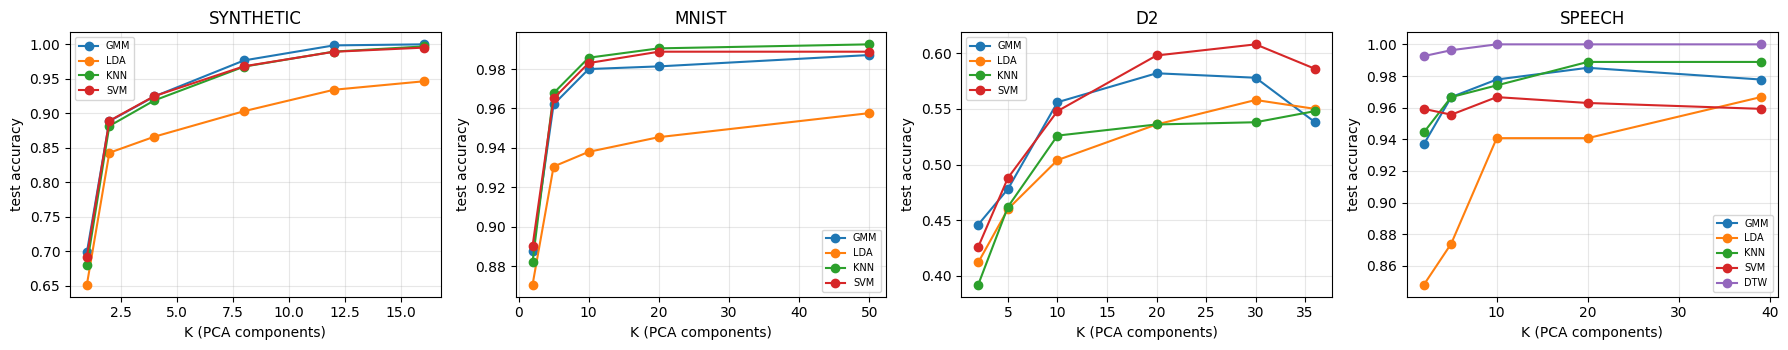

In [13]:
# RUN: after the dataset cells (works with whichever datasets have been run).
CLFS = ["GMM", "LDA", "KNN", "SVM", "DTW"]
names = [n for n in ["SYNTHETIC", "MNIST", "D2", "SPEECH"] if any(k[0] == n for k in RESULTS)]
print("TABLE 1 - test accuracy, raw features")
print("%-10s" % "dataset" + "".join("%9s" % c for c in CLFS))
for n in names: print("%-10s" % n + "".join("%9s" % ("%.4f" % RESULTS[(n, c, "raw")][1] if (n, c, "raw") in RESULTS else "N/A") for c in CLFS))
print("\nTABLE 2 - test accuracy with PCA features (K chosen on dev)")
for n in names:
    row = "%-10s" % n
    for c in CLFS:
        ks = [k[2] for k in RESULTS if k[0] == n and k[1] == c and k[2] != "raw"]
        if not ks: row += "%16s" % "N/A"; continue
        kb = max(ks, key=lambda K: (RESULTS[(n, c, K)][0], -K)); row += "%16s" % ("%.4f (K=%d)" % (RESULTS[(n, c, kb)][1], kb))
    print(row)
for n in names:
    ks = sorted(set(k[2] for k in RESULTS if k[0] == n and k[2] != "raw"))
    print("\nTABLE 3 [%s] - test accuracy for every K" % n)
    for K in ["raw"] + ks: print("%-6s" % K + "".join("%9s" % ("%.4f" % RESULTS[(n, c, K)][1] if (n, c, K) in RESULTS else "-") for c in CLFS))
fig, axes = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.6), squeeze=False)
for ax, n in zip(axes[0], names):
    ks = sorted(set(k[2] for k in RESULTS if k[0] == n and k[2] != "raw"))
    for c in CLFS:
        if (n, c, "raw") in RESULTS and ks: ax.plot(ks, [RESULTS[(n, c, K)][1] for K in ks], "o-", label=c)
    ax.set_title(n); ax.set_xlabel("K (PCA components)"); ax.set_ylabel("test accuracy"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Observations
Write these after reading the tables: best/worst classifier per dataset and why (class overlap, covariance shape, dimension vs sample count);
what ridge (`reg`, `lam`) the GMM/LDA needed; chosen k for K-NN; linear vs RBF and the SMO cap warnings for the SVM; DTW vs fixed-length classifiers on speech;
the smallest K that recovers the raw accuracy for each dataset and the variance it keeps.